# ¿Cómo elige Earlyscript los temas del día?

Cada día llegan miles de publicaciones sobre IA y programación. El motor de Earlyscript las lee y le muestra a Miguel **solo los temas que se están moviendo y que le sirven al canal**.

Este cuaderno lo muestra en cuatro pasos, con publicaciones reales de las cinco semanas anteriores al **9 de noviembre de 2026**.

*Para correrlo: Entorno de ejecución → Ejecutar todo. Tarda menos de un minuto y no necesita GPU.*

In [1]:
#@title Preparar el motor (código oculto)
import base64, io, html, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from datetime import datetime, timezone
from IPython.display import HTML, display
_z = np.load(io.BytesIO(base64.b64decode("...")))
DIA = 86400.0; CORTE = datetime(2026, 11, 9, tzinfo=timezone.utc).timestamp()
V = _z["V"].astype(np.float32); V /= np.linalg.norm(V, axis=1, keepdims=True); t = _z["ts"]
items = pd.DataFrame({"titulo": _z["title"], "fuente": _z["source"],
                      "fecha": pd.to_datetime(t, unit="s", utc=True), "edad": (CORTE - t) / DIA})
FUENTE = {"hn": "Hacker News", "github": "GitHub", "huggingface": "Hugging Face", "npm": "npm", "rss": "Blogs (RSS)"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# Paso 1: agrupar (coseno > 0,70 con el tema activo más parecido, en orden de fecha)
def agrupar(V, t, umbral=0.70, dias_activo=30):
    n, d = V.shape; C = np.zeros((n, d), np.float32); S = np.zeros((n, d)); ultimo = np.full(n, -np.inf)
    tema = np.empty(n, int); k = 0
    for i in range(n):
        act = np.flatnonzero(ultimo[:k] >= t[i] - dias_activo * DIA); j = -1
        if act.size:
            s = C[act] @ V[i]; m = int(np.argmax(s))
            if s[m] > umbral: j = int(act[m])
        if j < 0: j = k; k += 1
        S[j] += V[i]; C[j] = S[j] / np.linalg.norm(S[j]); ultimo[j] = t[i]; tema[i] = j
    return tema
items["tema"] = agrupar(V, t)

# Paso 3: relevancia (sonda logística sobre el vector Qwen)
items["relevancia"] = 1 / (1 + np.exp(-(V.astype(np.float64) @ _z["w"].astype(np.float64) + float(_z["b"]))))
P_inc = _z["inc"].astype(np.float32); P_inc /= np.linalg.norm(P_inc, axis=1, keepdims=True)
P_exc = _z["exc"].astype(np.float32); P_exc /= np.linalg.norm(P_exc, axis=1, keepdims=True)

# Paso 2: semanas, popularidad con decaimiento (vida media 7 días) y movimiento
def movimiento(w, primer, pop, p50, p90):
    n0, n1, n2, n3, n4 = w
    if n0 < 0.5 * n1 and n1 >= 3: return "en caída"
    if n1 < n2 and n0 >= n1 and n0 >= 3 and max(n1, n2, n3, n4) >= 5: return "rebote"
    if primer <= 7 and n0 >= 3: return "nueva"
    if pop >= p90 and n0 >= 8 and n0 >= n1: return "señal fuerte"
    if pop >= p50 and 3 <= n0 < 8 and (n0 >= 1.5 * n1 or n1 == 0): return "señal débil"
    return "estable"
def media_recortada(x):
    x = np.sort(np.asarray(x)); k = len(x) // 5; return float(np.mean(x[k:len(x) - k]))
filas = []
for k, g in items.groupby("tema"):
    e = g.edad.to_numpy(); w = np.bincount(np.minimum(e // 7, 5).astype(int), minlength=6)[:5]
    rec = g[g.edad < 7]; c = V[g.index].sum(0); c /= np.linalg.norm(c)
    filas.append(dict(tema=k, semanas=w, W0=w[0], W1=w[1], pop=float(np.sum(2.0 ** (-e / 7))), primer=e.max(),
                      relevancia=media_recortada((rec if len(rec) else g).relevancia),
                      incluye=(P_inc @ c).max(), excluye=(P_exc @ c).max(),
                      titulo=g.sort_values("relevancia").titulo.iloc[-1], fuentes=sorted(g.fuente.unique())))
T = pd.DataFrame(filas).set_index("tema")
p50, p90 = np.percentile(T[T.W0 >= 3]["pop"], [50, 90])
T["movimiento"] = [movimiento(r.semanas, r.primer, r.pop, p50, p90) for r in T.itertuples()]
T["perenne"] = [sum(n >= 5 for n in s) >= 3 for s in T.semanas]
T["excluido"] = (T.excluye >= 0.60) & (T.excluye > T.incluye)

# Paso 4: puntaje y listas
T["puntaje"] = T.relevancia + 0.25 * np.log((T.W0 + 1) / (T.W1 + 1)) + 0.15 * np.log1p(T.W0)
apto = (T.W0 >= 3) & ~T.excluido
en_movimiento = T[apto & ~T.perenne & T.movimiento.isin(["nueva", "señal débil", "señal fuerte", "rebote"])].sort_values("puntaje", ascending=False).head(10)
de_fondo = T[apto & T.perenne & (T.movimiento != "en caída")].sort_values("relevancia", ascending=False).head(5)
def tema_de(texto): return int(items[items.titulo.str.contains(texto, regex=False)].tema.iloc[0])
EJ = {"Copilot en JetBrains Air": tema_de("GitHub Copilot is now available in JetBrains Air"),
      "Kimi K3.1 Pro": tema_de("Kimi K3.1 Pro puts open-source AI"),
      "Agentes de programación": tema_de("Show HN: Evaluate and improve your agent steering")}
COLOR = dict(zip(EJ, ["#2a78d6", "#e5662c", "#1f9e74"]))
MAPA = {"Kimi K3.1 Pro": tema_de("Kimi K3.1 Pro puts open-source AI"),
        "Equipos de agentes": tema_de("Does a team of coding agents beat one agent?"),
        "Revisar los PR del agente": tema_de("Ask before you PR"),
        "Anthropic: detección de abuso": tema_de("Anthropic: Scaling Misuse Detection")}
COLOR_MAPA = dict(zip(MAPA, ["#e5662c", "#1f9e74", "#2a78d6", "#8e5bd0"]))
print(f"Listo: {len(items):,}".replace(",", ".") + f" publicaciones de {items.fuente.nunique()} fuentes, del {items.fecha.min():%d %b} al {items.fecha.max():%d %b}.")

Listo: 2.614 publicaciones de 5 fuentes, del 05 Oct al 08 Nov.


## 1. Agrupar: juntar lo que habla de lo mismo

Un modelo de lenguaje (Qwen3-Embedding) convierte cada titular en un punto. Los titulares que hablan de lo mismo quedan cerca, y el motor los junta en un **tema**.

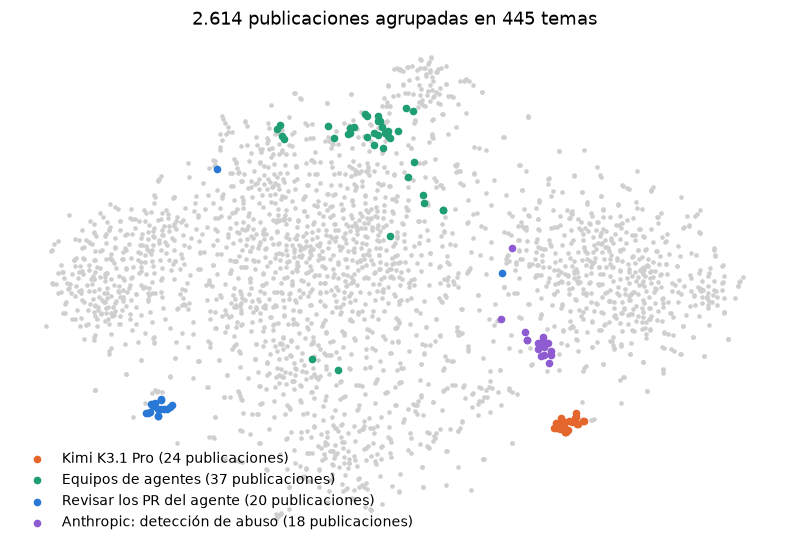

In [2]:
#@title Mapa de publicaciones
from sklearn.manifold import TSNE
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(V)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(xy[:, 0], xy[:, 1], s=4, c="#cfcfcf")
for nombre, k in MAPA.items():
    m = (items.tema == k).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=16, c=COLOR_MAPA[nombre], label=f"{nombre} ({m.sum()} publicaciones)")
ax.set_xticks([]); ax.set_yticks([]); ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title(f"{len(items):,} publicaciones agrupadas en {items.tema.nunique()} temas".replace(",", "."))
ax.legend(loc="lower left", fontsize=9, frameon=False); plt.show()
for nombre, k in MAPA.items():
    ejemplos = items[items.tema == k].sort_values("fecha").titulo.tail(3)
    display(HTML(f"<b style='color:{COLOR_MAPA[nombre]}'>{nombre}</b><br>" + "<br>".join("· " + html.escape(s) for s in ejemplos)))

## 2. ¿Se está moviendo?

El motor cuenta cuántas publicaciones tuvo cada tema en cada una de las últimas cinco semanas y le pone una etiqueta:

- **Nueva:** apareció esta semana.
- **Rebote:** había bajado y volvió a subir.
- **Estable de fondo:** lleva semanas con mucha actividad; es un tema permanente del sector.

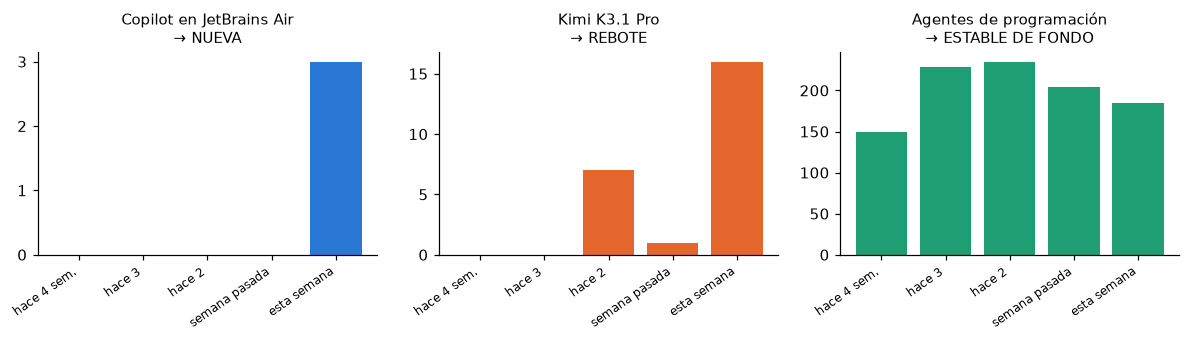

In [3]:
#@title Semanas de los tres temas de ejemplo
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
etiquetas = ["hace 4 sem.", "hace 3", "hace 2", "semana pasada", "esta semana"]
for ax, (nombre, k) in zip(axes, EJ.items()):
    r = T.loc[k]; ax.bar(range(5), r.semanas[::-1], color=COLOR[nombre])
    ax.set_xticks(range(5), etiquetas, rotation=35, ha="right", fontsize=8)
    mov = "estable de fondo" if r.perenne else r.movimiento
    ax.set_title(f"{nombre}\n→ {mov.upper()}", fontsize=10)
plt.tight_layout(); plt.show()

## 3. ¿Le sirve al canal?

Moverse no basta. Un modelo pequeño puntúa cada titular de 0 a 1 según cuánto le sirve al canal. Aprendió de 11.381 titulares de octubre, etiquetados por un juez LLM que antes se calibró contra las etiquetas de Miguel. Además, el **perfil del canal** descarta temas como política, criptomonedas o videojuegos.

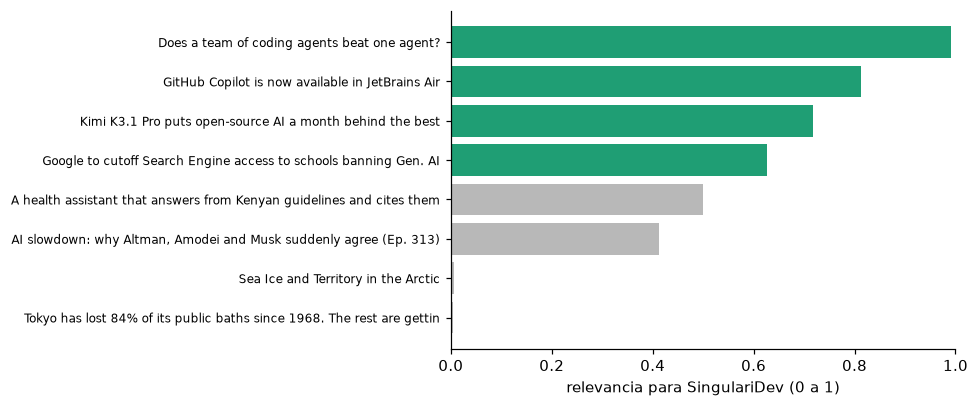

Temas descartados por el perfil del canal: 18


In [4]:
#@title Relevancia de algunos titulares
ejemplos = ["Does a team of coding agents beat one agent?", "GitHub Copilot is now available in JetBrains Air",
            "Kimi K3.1 Pro puts open-source AI", "Google to cutoff Search Engine", "A health assistant that answers",
            "AI slowdown: why Altman", "Sea Ice and Territory", "Tokyo has lost 84%"]
muestra = pd.concat([items[items.titulo.str.contains(s, regex=False)].head(1) for s in ejemplos]).sort_values("relevancia")
fig, ax = plt.subplots(figsize=(9, 3.8))
colores = ["#1f9e74" if v >= 0.5 else "#b8b8b8" for v in muestra.relevancia]
ax.barh([s[:70] for s in muestra.titulo], muestra.relevancia, color=colores)
ax.set_xlim(0, 1); ax.set_xlabel("relevancia para SingulariDev (0 a 1)"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
print(f"Temas descartados por el perfil del canal: {int(T.excluido.sum())}")

## 4. Resultado: las tarjetas del día

El motor junta las dos cosas, movimiento y relevancia, y arma dos listas. Esto es lo que Miguel ve en la pantalla de Tendencias.

In [5]:
#@title Tarjetas
BADGE = {"nueva": "#2a78d6", "rebote": "#e5662c", "señal débil": "#8e5bd0", "señal fuerte": "#c0392b", "estable": "#1f9e74"}
def tarjetas(df, titulo, n):
    out = [f"<h3 style='margin:14px 0 6px'>{titulo}</h3><div style='display:flex;flex-wrap:wrap;gap:10px'>"]
    for _, r in df.head(n).iterrows():
        mov = "de fondo" if r.perenne else r.movimiento; col = BADGE.get(r.movimiento, "#777")
        fuentes = ", ".join(FUENTE[f] for f in r.fuentes)
        out.append(f"""<div style='width:270px;border:1px solid #ddd;border-radius:10px;padding:10px 12px;font-family:sans-serif'>
          <span style='background:{col};color:white;border-radius:10px;padding:1px 8px;font-size:11px'>{mov}</span>
          <div style='font-weight:600;margin:6px 0;font-size:13px'>{html.escape(r.titulo[:90])}</div>
          <div style='font-size:11px;color:#555'>{r.W0} publicaciones esta semana · {fuentes}</div>
          <div style='font-size:11px;color:#555;margin-top:4px'>relevancia
            <span style='display:inline-block;width:100px;height:7px;background:#eee;border-radius:4px;vertical-align:middle'>
            <span style='display:block;width:{r.relevancia*100:.0f}px;height:7px;background:#1f9e74;border-radius:4px'></span></span> {r.relevancia:.2f}</div></div>""")
    return "".join(out) + "</div>"
display(HTML(tarjetas(en_movimiento, "En movimiento", 6) + tarjetas(de_fondo, "De fondo", 3)))

## 5. La oportunidad: llegar antes de que sea tendencia

Esta es la idea que el motor toma de **BERTrend** (Boutaleb, Picault y Grosjean, 2024). Cada tema tiene una **popularidad con memoria**: cada publicación suma 1 y pierde la mitad de su peso cada 7 días. Cada día, el motor compara esa popularidad con la de todos los temas activos:

- **Ruido:** por debajo de la mediana.
- **Señal débil:** sobre la mediana, pero todavía fuera del 10 % superior. El tema empieza a sonar.
- **Señal fuerte:** en el 10 % superior. Ya es tendencia.

La oportunidad está en la **señal débil que sigue subiendo**: preparar el video mientras el tema crece, para estar presente cuando explote.

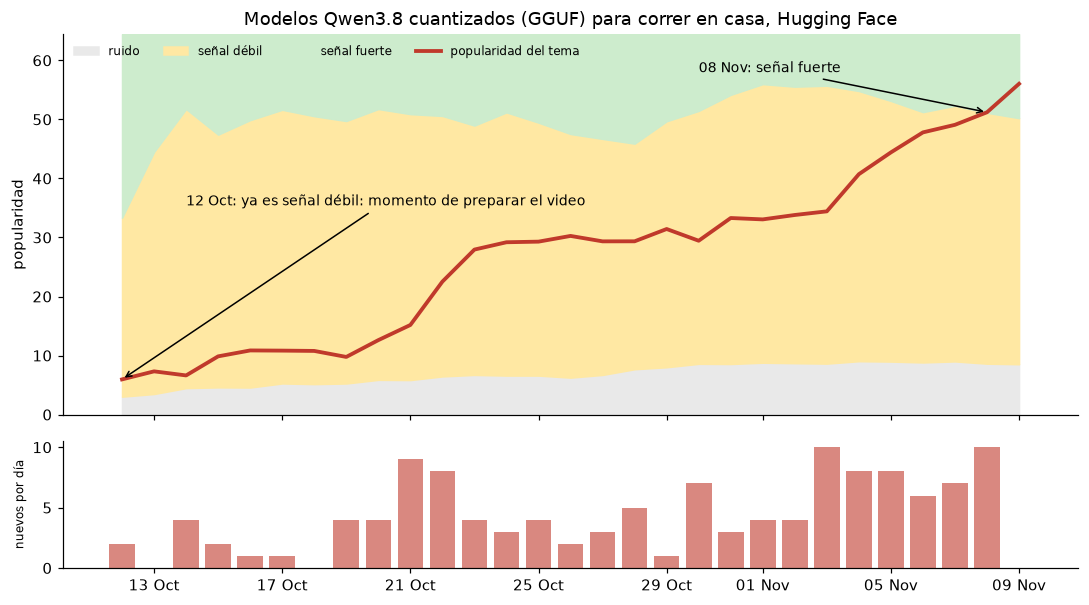

El motor lo tenía como señal débil 27 días antes de que fuera tendencia. Algunos modelos del tema:
  · autor_0170/Qwen3.8-4B-Distill-ARA-Abliterated
  · autor_0171/qwen-concept-27b
  · autor_0172/Qwen3.8-27B-TURBO-Fable-Cold-Fusion-735-882-Heretic-Uncensored-NEO-CODER-MAX-MTP-GGUF
  · autor_0173/QwenFX
  · autor_0110/ThinkingCap-Qwen3.8-Flash-Next-GGUF


In [6]:
#@title Termómetro de un tema real
import json
ej = json.loads(r"""{"ts": [1791189996, 1791309605, 1791355742, 1791394417, 1791445393, 1791708370, 1791718454, 1791745355, 1791812876, 1791820188, 1791954499, 1791978460, 1792011104, 1792016122, 1792074918, 1792081785, 1792189614, 1792254402, 1792377946, 1792396341, 1792396714, 1792435899, 1792466774, 1792476561, 1792485737, 1792512903, 1792567754, 1792589505, 1792592458, 1792612816, 1792612956, 1792613097, 1792613750, 1792616178, 1792627189, 1792627646, 1792645875, 1792655675, 1792656662, 1792675253, 1792677317, 1792682116, 1792682912, 1792758594, 1792772637, 1792777264, 1792781188, 1792809143, 1792850433, 1792869267, 1792900261, 1792900910, 1792907014, 1792938145, 1793001970, 1793056524, 1793059200, 1793060978, 1793111162, 1793189256, 1793197100, 1793205282, 1793215993, 1793218462, 1793299665, 1793318400, 1793319160, 1793326689, 1793360572, 1793384500, 1793390722, 1793392608, 1793419251, 1793482563, 1793486772, 1793502189, 1793555681, 1793556988, 1793572001, 1793612568, 1793618249, 1793620187, 1793630879, 1793677146, 1793688429, 1793690998, 1793691623, 1793710625, 1793717774, 1793719259, 1793720551, 1793731204, 1793742656, 1793760081, 1793767839, 1793768024, 1793772913, 1793773118, 1793793378, 1793809285, 1793826686, 1793838640, 1793861776, 1793870040, 1793870083, 1793871687, 1793893649, 1793895911, 1793901231, 1793934113, 1793950146, 1793974071, 1794001160, 1794002326, 1794005413, 1794035681, 1794048848, 1794059551, 1794062167, 1794066550, 1794085319, 1794095173, 1794129356, 1794132284, 1794146788, 1794146844, 1794150656, 1794152676, 1794155983, 1794158635, 1794159521, 1794179537], "titulos": ["autor_0010/Jackrong_Qwopus3.8-27B-Coder-Flash-GGUF", "autor_0165/Qwen3.8-Flash-Next-AD-gateup-GGUF", "autor_0166/plamo-3-translate-0.8b-mlx-4bit-compact", "autor_0082/Arete-27B-GGUF", "autor_0167/Qwen3.6-35B-A3B-Uncensored-LoRA-GGUF", "autor_0168/Qwen3.8-27B-DSpine-b16-GGUF", "autor_0169/OrcaCyber-Nano-1.0-Turbo-cmf", "autor_0170/Qwen3.8-4B-Distill-ARA-Abliterated", "autor_0171/qwen-concept-27b", "autor_0172/Qwen3.8-27B-TURBO-Fable-Cold-Fusion-735-882-Heretic-Uncensored-NEO-CODER-MAX-MTP-GGUF", "autor_0173/QwenFX", "autor_0110/ThinkingCap-Qwen3.8-Flash-Next-GGUF"], "dias": [1791763200, 1791849600, 1791936000, 1792022400, 1792108800, 1792195200, 1792281600, 1792368000, 1792454400, 1792540800, 1792627200, 1792713600, 1792800000, 1792886400, 1792972800, 1793059200, 1793145600, 1793232000, 1793318400, 1793404800, 1793491200, 1793577600, 1793664000, 1793750400, 1793836800, 1793923200, 1794009600, 1794096000, 1794182400], "p50": [3.038, 3.487, 4.485, 4.61, 4.586, 5.274, 5.161, 5.267, 5.884, 5.85, 6.465, 6.721, 6.607, 6.606, 6.26, 6.718, 7.682, 8.019, 8.598, 8.568, 8.785, 8.704, 8.633, 9.041, 8.979, 8.831, 9.007, 8.623, 8.529], "p90": [33.351, 44.504, 51.763, 47.425, 49.883, 51.635, 50.549, 49.732, 51.762, 50.899, 50.592, 48.961, 51.197, 49.456, 47.532, 46.704, 45.897, 49.693, 51.443, 54.168, 55.984, 55.547, 55.713, 54.814, 53.132, 51.237, 52.322, 51.131, 50.218]}""")
dias = pd.to_datetime(ej["dias"], unit="s", utc=True); ts = np.array(ej["ts"], float)
pop = np.array([np.sum(2.0 ** (-((d - ts[ts < d]) / DIA) / 7)) for d in ej["dias"]])
p50, p90 = np.array(ej["p50"]), np.array(ej["p90"])
techo = max(pop.max(), p90.max()) * 1.15
debil = next(i for i in range(len(pop)) if pop[i] >= p50[i]); fuerte = next(i for i in range(len(pop)) if pop[i] >= p90[i])
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.fill_between(dias, 0, p50, color="#e9e9e9", label="ruido")
ax.fill_between(dias, p50, p90, color="#ffe8a3", label="señal débil")
ax.fill_between(dias, p90, techo, color="#cdeccd", label="señal fuerte")
ax.plot(dias, pop, color="#c0392b", lw=2.5, label="popularidad del tema")
ax.annotate(f"{dias[debil]:%d %b}: ya es señal débil: momento de preparar el video", (dias[debil], pop[debil]),
            xytext=(dias[debil + 2], techo * 0.55), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate(f"{dias[fuerte]:%d %b}: señal fuerte", (dias[fuerte], pop[fuerte]),
            xytext=(dias[fuerte - 9], techo * 0.9), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_ylim(0, techo); ax.set_ylabel("popularidad"); ax.legend(loc="upper left", fontsize=8, ncol=4, frameon=False)
ax.set_title("Modelos Qwen3.8 cuantizados (GGUF) para correr en casa, Hugging Face")
por_dia = pd.Series(1, index=pd.to_datetime(ts, unit="s", utc=True)).resample("D").sum().reindex(dias, fill_value=0)
ax2.bar(dias, por_dia, color="#c0392b", alpha=0.6); ax2.set_ylabel("nuevos por día", fontsize=8)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()
print(f"El motor lo tenía como señal débil {(dias[fuerte] - dias[debil]).days} días antes de que fuera tendencia. Algunos modelos del tema:")
for s in ej["titulos"][-5:]: print("  ·", s)

**¿Funciona siempre?** No todavía. En el desarrollo del motor, en 21 cortes de octubre, el motor captó 8 de 50 despegues, y solo la mitad a tiempo. Hoy la señal débil le sirve a Miguel como alerta, y la decisión sigue siendo suya. Medir y mejorar esa anticipación es **trabajo futuro**: más fuentes, más historia y una evaluación prospectiva con los videos publicados.

## Y después

En la app, Miguel elige una tarjeta y abre un hilo de video: un asistente escribe el guion con citas a las fuentes y Miguel decide si lo produce. En los seis pares del estudio, ese flujo asistido redujo el tiempo mediano de 29 a 10 minutos frente al trabajo manual.

---

### Anexo: cómo funciona por dentro

- **Agrupar.** Cada publicación se une al tema activo más parecido si el coseno supera 0,70; si no, abre un tema. Un tema sin publicaciones en 30 días se cierra.
- **Movimiento.** W0 es esta semana y W1 la anterior. En caída: W0 < W1/2. Rebote: W1 < W2 y W0 ≥ W1. Nueva: primer ítem hace ≤ 7 días. Señal fuerte o débil: según la popularidad con decaimiento (cada ítem vale la mitad cada 7 días, al estilo BERTrend). Un tema con tres o más semanas de 5 o más ítems es perenne y va a *De fondo*.
- **Relevancia.** Regresión logística sobre el vector Qwen de cada titular, entrenada con 11.381 titulares del 1 al 11 de octubre etiquetados por el juez LLM v2 (acuerdo 0,84 con Miguel). La del tema es la media recortada de su última semana.
- **Puntaje de En movimiento.** relevancia + 0,25 · ln((W0+1)/(W1+1)) + 0,15 · ln(1+W0). *De fondo* se ordena por relevancia.
- **Termómetro (sección 5).** Umbrales de mediana y 10 % superior calculados cada día sobre los temas activos (3 o más publicaciones en 7 días) de las 36.808 publicaciones del corte, con los temas tal como quedaron el 9 de noviembre.
- **Datos.** 2.614 publicaciones reales (Hacker News, GitHub, Hugging Face, npm y blogs) del 5 de octubre al 8 de noviembre de 2026, con los vectores que calculó el motor. Es una muestra de las 36.808 del corte.
- **Versión didáctica.** El motor real está en TypeScript (Earlyscript, `trend-engine`, configuración `engine.v3-sel`). Este cuaderno omite el historial previo a 35 días, la regla de cobertura por fuente, la fusión de temas duplicados y dos puestos reservados por trayectoria. Sus listas se parecen a las de la app, pero no son idénticas.